# Discrete Fourier Transform
Fourier analysis is a family of mathematical techniques, all based on decomposing signals into sinusoids. The Discrete Fourier Transform (DFT) is the family member used with digitized signals. In this notebook we focus on the real DFT, a version of the discrete Fourier transform that uses real numbers to represent the input and output signals. 

The Discrete Fourier Transform, DFT, changes an N point input signal into two point output signals. The input signal contains the signal being decomposed, while the two output signals contain the amplitudes of the component sine and cosine waves. The input signal is said to be in the time domain and the output signal in the frequency domain.

The frequency domain contains exactly the same information as the time domain, just in a different form. If you know one domain, you can calculate the other. Given the time domain signal, the process of calculating the frequency domain is called **decomposition**, **analysis**, the **forward DFT**, or simply, the **DFT**. If you know the frequency domain, calculation of the time domain is called **synthesis**, or the **inverse DFT**. 

The number of samples in the time domain is usually represented by the variable $N$. While $N$ can be any positive integer, a power of two is usually chosen, i.e., 128, 256, 512, 1024, etc. There are two reasons for this. First, digital data storage uses binary addressing, making powers of two a natural signal length. Second, the most efficient algorithm for calculating the DFT, the Fast Fourier Transform (FFT), usually operates with $N$ that is a power of two. Typically, $N$ is selected between 32 and 4096. In most cases, the samples run from $0$ to $N-1$, rather than $1$ to $N$. 

Time domain signals usually uses lower cases notation and frequency domain signals uses upper case notation, therefore a signal $x[n]$ said to be in the time domain and $X[n]$ is in the frequency domain. The frequency domain signal $X[n]$ consists of two parts, each of $N/2 +1$ samples. These are called the **Real** part of $X[ ]$ , written as: $\mathbf{Re}X[n]$, and the **Imaginary** part of $X[ ]$, written as: $\mathbf{Im}X[ ]$. The values in $\mathbf{Re}X[ ]$ are the amplitudes of the cosine waves, while the values in $\mathbf{Im}X[ ]$ are the amplitudes of the sine waves. Just as the time domain runs from $x[n]$ to $x[N-1]$, the frequency domain signals run from $\mathbf{Re}X[0]$ to $\mathbf{Re}X[N/2]$, and from $\mathbf{Im}X[0]$ to $\mathbf{Im}X[N/2]$.

## Calculating the DFT
The analysis equation for calculating the DFT can be performed as follows

$$\mathbf{Re}X[k] = \sum^{N-1}_{i=0}x[i]\cos{(2\pi ki/N)}$$
$$\mathbf{Im}X[k] = -\sum^{N-1}_{i=0}x[i]\sin{(2\pi ki/N)}$$

In these equations, $x[i]$ is the time domain signal being analyzed, and $\mathbf{Re}X[k]$ and $\mathbf{Im}X[k]$ are the frequency domain signals being calculated. The index $i$ runs from $0$ to $N-1$, while the index $k$ runs from $0$ to $N/2$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pickle

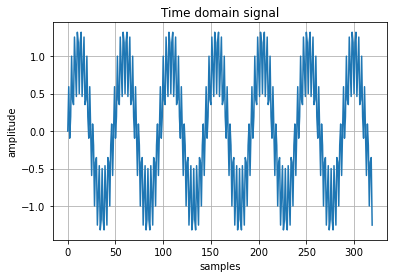

In [2]:
plt.rcParams['figure.figsize'] = (10,5)

file = {'x':'Signals/InputSignal_f32_1kHz_15kHz.dat'}

x = np.loadtxt(file['x'])
N,M = x.shape
x = x.reshape(N*M, 1)

plt.plot(x)
plt.xlabel('samples')
plt.ylabel('amplitude')
plt.title('Time domain signal')
plt.grid('on')
plt.show()

###  Function implementation of the DFT 
Implement the DFT algorithm using the analysis equation described before.

In [3]:
def dft(x):
    """ 
    Function that calculates the DFT of an input signal x.
  
    Parameters: 
    x (numpy array): Array of numbers representing the input signal to be transformed.
  
    Returns: 
    rex (numpy array): Real DFT part of input signal x
    imx (numpy array): Imaginary DFT part of input signal x
  
    """
    
    N = len(x)
    M = int(N/2) + 1
    rex = np.zeros((M,1))
    imx = np.zeros((M,1))
    
    ### BEGIN SOLUTION

    for k in range(M):
        for i in range(N):
            rex[k][0] = rex[k][0] + x[i][0]*np.cos(2*np.pi*k*i/N)
            imx[k][0] = imx[k][0] - x[i][0]*np.sin(2*np.pi*k*i/N)
    ### END SOLUTION        
    
    return rex, imx    

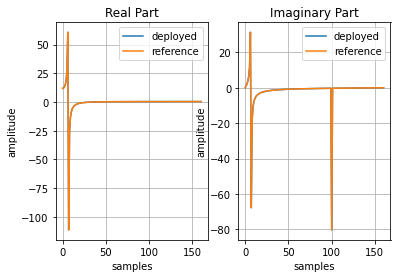

In [4]:
rex, imx = dft(x)

re_fft, imag_fft = np.real(np.fft.fft2(x)), np.imag(np.fft.fft2(x))


plt.subplot(1,2,1)
plt.plot(rex, label='deployed')
plt.plot(re_fft[:int(len(re_fft)/2)+1], label='reference')
plt.title('Real Part')
plt.xlabel('samples')
plt.ylabel('amplitude')
plt.grid('on')
plt.legend()

plt.subplot(1,2,2)
plt.plot(imx, label='deployed')
plt.plot(imag_fft[:int(len(re_fft)/2)+1], label='reference')
plt.title('Imaginary Part')
plt.xlabel('samples')
plt.ylabel('amplitude')
plt.grid('on')
plt.legend()

plt.show()



assert np.isclose(rex, re_fft[:int(len(re_fft)/2)+1]).all()

### Polar Notation

As it has been described so far, the frequency domain is a group of amplitudes of cosine and sine waves (with slight scaling modifications). This is called rectangular notation. Alternatively, the frequency domain can be expressed in polar form. In this notation, $\mathbf{Re}X[]$ & $\mathbf{Im}X[]$ are replaced with two other arrays, called the Magnitude of $X[ ]$ , written in equations as: $\mathbf{Mag} X[ ]$, and the Phase of $X[ ]$, written as: $\mathbf{Phase} X[ ]$.

The following equations show how to convert from rectangular to polar notation:

$$\mathbf{Mag}X[k] = \left( \mathbf{Re}X[k]^2 + \mathbf{Im}X[k]^2 \right)^{1/2}$$

$$\mathbf{Phase}X[k] = \arctan\frac{\mathbf{Im}X[k]}{\mathbf{Re}X[k]}$$


The following equations show how to convert from polar to rectangular notation:

$$\mathbf{Re}X[k] = \mathbf{Mag}X[k]\cos{(\mathbf{Phase}X[k])}$$

$$\mathbf{Im}X[k] = \mathbf{Mag}X[k]\sin{(\mathbf{Phase}X[k])}$$

###  Function implementation of polar notation
Implement the polar notation for the DFT algorithm using the equations for $\mathbf{Mag}X[k]$ and $\mathbf{Phase}X[k]$.

In [5]:
def dft_magnitude(rex, imx):
    """ 
    Function that calculates the magnitude of an real and imaginary signal x.
  
    Parameters: 
    rex (numpy array): Array of numbers representing the real part of the DFT signal.
    imx (numpy array): Array of numbers representing the imaginary part of the DFT signal.
  
    Returns: 
    numpy array: Returns magnitude of the real and imaginary signal.
  
    """
    ### BEGIN SOLUTION
    return np.sqrt(rex**2 + imx**2)
    ### END SOLUTION
        
    
def dft_phase(rex, imx):
    """ 
    Function that calculates the phase of an real and imaginary signal x.
  
    Parameters: 
    rex (numpy array): Array of numbers representing the real part of the DFT signal.
    imx (numpy array): Array of numbers representing the imaginary part of the DFT signal.
  
    Returns: 
    numpy array: Returns phase of the real and imaginary signal.
  
    """
    ### BEGIN SOLUTION
    return np.arctan(imx/rex)  
    ### END SOLUTION

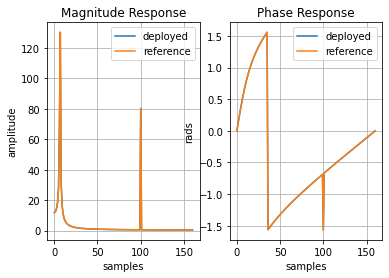

In [6]:
magx = dft_magnitude(rex, imx)
phasex = dft_phase(rex, imx)

mag_fft = np.abs(np.fft.fft2(x))
phase_fft = np.arctan(np.imag(np.fft.fft2(x))/np.real(np.fft.fft2(x)))
M = int(len(mag_fft)/2)+1

plt.subplot(1,2,1)
plt.plot(magx, label='deployed')
plt.plot(magx[:M], label='reference')
plt.title('Magnitude Response')
plt.xlabel('samples')
plt.ylabel('amplitude')
plt.grid('on')
plt.legend()

plt.subplot(1,2,2)
plt.plot(phasex, label='deployed')
plt.plot(phase_fft[:M], label='reference')
plt.title('Phase Response')
plt.xlabel('samples')
plt.ylabel('rads')
plt.grid('on')
plt.legend()

plt.show()


assert np.isclose(magx, mag_fft[:M]).all()

assert np.isclose(phasex, phase_fft[:M]).all()

### Polar Drawbacks

#### 1: Radians vs. Degrees
It is possible to express the phase in either degrees or radians. When expressed in degrees, the values in the phase signal are between -180 and 180. Using radians, each of the values will be between $-\pi$ and $\pi$.

#### 2: Divide by zero error
When converting from rectangular to polar notation, it is very common to find frequencies where the real part is zero and the imaginary part is some nonzero value. This simply means that the phase is exactly 90 or -90 degrees. To avoid this problem, the real part must be tested for being zero before the division. If it is zero, the imaginary part must be tested for being positive or negative, to determine whether to set the phase to $\pi /2$ or $-\pi /2$, respectively. Lastly, the division just needs to be bypassed.

#### 3: Incorrect arctan
This error occurs whenever the real part is negative. This problem can be corrected by testing the real and imaginary parts after the phase has been calculated. If both the real and imaginary parts are negative, subtract 180 (or $\pi$ radians) from the calculated phase. If the real part is negative and the imaginary part is positive, add 180 (or $\pi$ radians).

#### 4: Phase of very small magnitudes
If the magnitude is negligibly small, the phase doesn't have any meaning, and can assume unusual values.
![Phase of a small magnitude signal](Images/nuisance4.gif)

#### 5: $2\pi$ ambiguity of the phase
Every time a point looks as if it is going to dip below $-\pi$, it snaps back to $\pi$. This is a result of the periodic nature of sinusoids. For example, a phase shift of $\theta$, is exactly the same as a phase shift of $\theta + 2\pi$, $\theta + 4\pi$, $\theta + 6\pi$, etc. Any sinusoid is unchanged when you add an integer multiple of $2\pi$ to the phase. The apparent discontinuities in the signal are a result of the computer algorithm picking its favorite choice from an infinite number of equivalent possibilities. The smallest possible value is always chosen, keeping the phase between $-\pi$ and $\pi$. Sometimes is good to solve this issue by implementing a technique called **unwrapping the phase** which extends the phase above $\pi$ or below $-\pi$. The idea behind this algorithm is as follows: a multiple of $2\pi$ is added or subtracted from each value of the phase based on a minimization of the difference between adjacent samples.

#### 6: The magnitude is always positive ($\pi$ ambiguity of the phase)
The following figure shows a frequency domain signal in rectangular and polar form. The real part is smooth and quite easy to understand, while the imaginary part is entirely zero. In comparison, the polar signals contain abrupt discontinuities and sharp corners. This is because the magnitude must always be positive, by *definition*. Whenever the real part dips below zero, the magnitude remains positive by changing the phase by $\pi$ (or $-\pi$, which is the same thing).

![Rectangular and polar form of a signal](Images/nuisance6.gif)

One solution is to allow the magnitude to have negative values while the phase would be entirely zero. We will use the term **unwrapped magnitude** to indicate a "magnitude" that is allowed to have negative values. 

#### 7: Spikes between $\pi$ and $-\pi$
Since $\pi$ and $-\pi$ represent exactly the same phase shift, round-off noise can cause adjacent points in the phase to rapidly switch between the two values. As shown in the previous figure (d), this can produce sharp breaks and spikes in an otherwise smooth curve. Don't be fooled, the phase isn't really this discontinuous.

###  Correcting polar drawbacks
Now that you have seen the different drawbacks that might occur during the polar implementation of the DFT, it is your time to implement some auxiliary functions to solve these issues.  

First you will implement the function `arctan_correct` which fixes the drawback number 3.

In [7]:
def arctan_correct(rex, imx, phase):
    """ 
    Function that corrects the arctan calculation. If both the real and 
    imaginary parts are negative, subtract 180 (or 𝜋 radians) from the
    calculated phase. If the real part is negative and the imaginary part
    is positive, add 180 (or 𝜋 radians)
  
    Parameters: 
    rex (numpy array): Array of numbers representing the real part of the DFT signal.
    imx (numpy array): Array of numbers representing the imaginary part of the DFT signal.
    phase (numpy array): Array of numbers representing the phase of the DFT signal.
  
    Returns: 
    numpy array: Returns corrected arctan calculation of phase.
  
    """
    
    N = rex.shape[0]
    output = np.copy(phase)
    
    ### BEGIN SOLUTION

    for i in range(N):
        if rex[i][0]<0:
            if imx[i][0]<0:
                output[i]=phase[i] - np.pi
                #print('minus pi correction')
            elif imx[i][0]>0:
                output[i]=phase[i] + np.pi
                #print('plus pi correction')
                
    ### END SOLUTION
    return output

Here you can test your `arctan_correct` function implementation, don't worry about the division by zero warning, you will fix this soon. Try to understand what is happening.

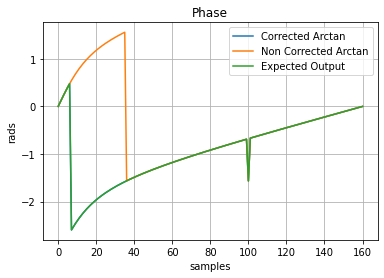

In [8]:
rex, imx = dft(x)
output = arctan_correct(rex, imx, np.arctan(imx/rex))

angle = np.angle(np.fft.fft2(x))
M = int(len(angle)/2)+1

plt.plot(output, label='Corrected Arctan');
plt.plot(dft_phase(rex, imx), label='Non Corrected Arctan');
plt.plot(angle[:M], label='Expected Output')
plt.title('Phase')

plt.xlabel('samples')
plt.ylabel('rads')

plt.grid()
plt.legend()
plt.show()

assert np.isclose(output, angle[:M]).all()

Now you will develop the `unwrap` function which solves drawback number 5.

In [9]:
def unwrap(phase):
    """ 
    Function that ensures that all appropriate multiples of 2𝜋 have been included.
  
    Parameters: 
    phase (numpy array): Array of numbers representing the phase of the DFT signal.
  
    Returns: 
    numpy array: Returns unwrapped phase.
  
    """
    
    N = phase.shape[0]
    uwphase = np.zeros(phase.shape)
    
    ### BEGIN SOLUTION    
    for i in range(N):
        c = np.round((uwphase[i-1][0]-phase[i][0])/(2*np.pi))#.astype('int')
        uwphase[i] = phase[i] + c*2*np.pi
    
    ### END SOLUTION
    return uwphase

Here you can test your `unwrap` function implementation. Can you understand what is happening now?

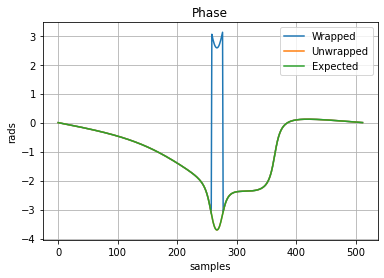

In [10]:
file = {'h':'Signals/filter_response.dat'}

h = np.loadtxt(file['h'])

N = h.shape[0]
h = h.reshape(N, 1)

h_unwrapped = unwrap(h)
h_numpy_unwrapped = np.unwrap(h, axis=0)

plt.plot(h, label='Wrapped')
plt.plot(h_unwrapped, label='Unwrapped')
plt.plot(h_numpy_unwrapped, label='Expected')
plt.title('Phase')
plt.xlabel('samples')
plt.ylabel('rads')

plt.grid()
plt.legend()
plt.plot()

assert np.isclose(h_unwrapped, h_numpy_unwrapped).all()

Lastly you will again implement your `dft_phase` function, but now you will have to take into account the following drawbacks: 
* division by zero
* incorrect arctan calculation 
* phase ambiguity

In [11]:
def dft_phase(rex, imx, correct_arctan=True, correct_unwrap=True):
    """ 
    Function that calculates the phase of an real and imaginary signal x. 
    Solving the different drawbacks that might occur.
  
    Parameters: 
    rex (numpy array): Array of numbers representing the real part of the DFT signal.
    imx (numpy array): Array of numbers representing the imaginary part of the DFT signal.
    correct_arctan (boolean): If True arctan correction is performed.
    correct_unwrap (boolean): If True phase abiguity correction is performed.
  
    Returns: 
    numpy array: Returns phase of the real and imaginary signal.
  
    """
    N = rex.shape[0]
    
    #SOLVE Drawback 2: Divide by zero error
    ### BEGIN SOLUTION  
    rex[rex==0] = 1e-18
    phase = np.arctan(imx/rex)
    ### END SOLUTION
    
    #SOLVE Drawback 3: Incorrect arctan
    ### BEGIN SOLUTION  
    if correct_arctan==True:
        phase_correct = arctan_correct(rex, imx, phase)
    else:
        phase_correct = phase
    ### END SOLUTION
                    
    #SOLVE Drawback 5: 2𝜋 ambiguity of the phase 
    ### BEGIN SOLUTION  
    if correct_unwrap==True:
        uwphase = unwrap(phase_correct)
    else:
        uwphase = phase_correct
    ### END SOLUTION
    
    return uwphase

Finally you will test your `dft_phase` implementation and plot it's results.

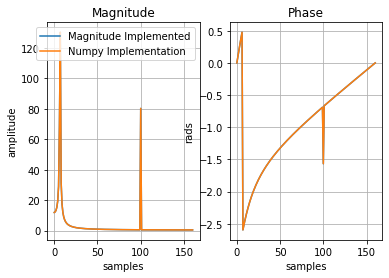

In [12]:
magx = dft_magnitude(rex, imx)
phasex = dft_phase(rex, imx, correct_arctan=True, correct_unwrap=True)

magx_numpy = np.absolute(np.fft.fft2(x))
phasex_numpy = np.angle(np.fft.fft2(x))

M = int(len(magx_numpy)/2)+1

plt.subplot(1,2,1)
plt.plot(magx, label='Magnitude Implemented')
plt.plot(magx_numpy[:M], label='Numpy Implementation')
plt.title('Magnitude')
plt.xlabel('samples')
plt.ylabel('amplitude')
plt.legend()
plt.grid()

plt.subplot(1,2,2)
plt.plot(phasex, label='Correctd Phase')
plt.plot(phasex_numpy[:M], label='Numpy Implementation')
plt.title('Phase')
plt.xlabel('samples')
plt.ylabel('rads')
plt.grid()


plt.show()

assert np.isclose(magx, magx_numpy[:M]).all()
assert np.isclose(phasex, phasex_numpy[:M]).all()

### Comparison of our results with Scipy
In this part we will compare our previous results with the Fourier Transform implementation of SciPy. SciPy provides many user-friendly and efficient numerical routines, such as routines for numerical integration, interpolation, optimization, linear algebra, and statistics.

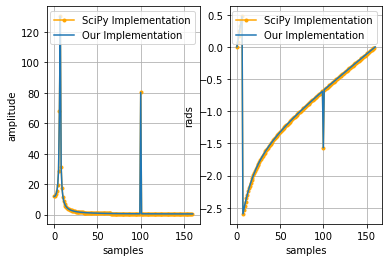

In [13]:
from scipy.fftpack import fft

#SciPy Calculations
y =fft(x.flatten())
mag = np.absolute(y)
phase = np.arctan2(np.imag(y),np.real(y)) #We use -imag to be consisten with our definition

#Our Implementation
rex, imx = dft(x)
magx = dft_magnitude(rex, imx)
phasex = dft_phase(rex, imx)

plt.subplot(1,2,1)
plt.plot(mag[0:160], '.-', color = 'orange', label='SciPy Implementation');
plt.plot(magx, label='Our Implementation')
plt.xlabel('samples')
plt.ylabel('amplitude')
plt.grid()
plt.legend()

plt.subplot(1,2,2)
plt.plot(phase[0:160], '.-', color = 'orange', label='SciPy Implementation');
plt.plot(phasex, label='Our Implementation')
plt.xlabel('samples')
plt.ylabel('rads')
plt.grid()
plt.legend()

plt.show()

### The Frequency Domain's Independent Variable
The horizontal axis of the frequency domain can be referred to in four different ways, all of which are common in DSP. We can label our horizontal axis as follows:
1. The number of samples from $0$ to $N/2$
2. A fraction of the sampling rate between $0$ to $0.5$
3. The natural frequency $\omega$
4. The analog frequencies used in a particular application

In this part you will develop a function called `frequency_domain` which takes as input a signal in the Fourier domain and returns one of the four frecuency domains described earlier.

In [14]:
def frequency_domain(x, style='fraction', **kwargs):
    """ 
    Function that calculates the frequency domain independent variable.

    Parameters: 
    x (numpy array): Array of numbers representing the input signal inthe Fourier domain
    to  obtain the frequency independent variable.
    style (string): String value that selects between frequency domain's 
    independent variable.
        'samples' returns number of samples between 0 to N/2
        'fraction' returns a fraction of the sampling rate between 0 to 0.5
        'natural' returns the natural frequency between 0 and pi.
        'analog' returns analog frequency between 0 and fsamp/2
    fsamp (float): Float value representing the sampling frequency. 
        (Only used for 'analog' style).

    Returns: 
    numpy array: Returns frequency domain's independent variable.

        """
    N = x.shape[0]
    t = np.arange(N)
    
    ### BEGIN SOLUTION
       
    if(style=='fraction'):
        return t/(2*(N-1))
    elif(style=='natural'):
        return np.pi*(t/(2*(N-1)))
    elif(style=='analog'):
        return kwargs['fsamp']*(t/(2*(N-1)))
    elif(style=='samples'):
        return t
    else:
        return t
    
    ### END SOLUTION

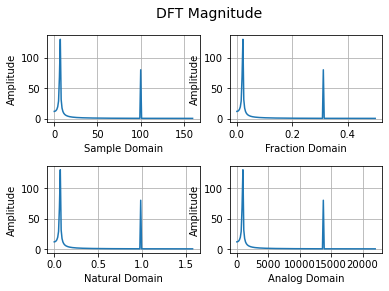

In [15]:
fraction_domain = frequency_domain(magx, style='fraction')
natural_domain = frequency_domain(magx, style='natural')
analog_domain = frequency_domain(magx, style='analog', fsamp=44000)

plt.suptitle("DFT Magnitude", fontsize=14)
plt.subplot(2,2,1)
plt.plot(magx)
plt.xlabel('Sample Domain')
plt.ylabel('Amplitude')
plt.grid()

plt.subplot(2,2,2)
plt.plot(fraction_domain, magx)
plt.xlabel('Fraction Domain')
plt.ylabel('Amplitude')
plt.grid()

plt.subplot(2,2,3)
plt.plot(natural_domain, magx)
plt.xlabel('Natural Domain')
plt.ylabel('Amplitude')
plt.grid()

plt.subplot(2,2,4)
plt.plot(analog_domain, magx)
plt.xlabel('Analog Domain')
plt.ylabel('Amplitude')
plt.grid()
plt.subplots_adjust(hspace = 0.5)
plt.show()


with open('domains.pkl', 'rb') as file:
    domains = pickle.load(file)
       
fraction_domain_pkl = domains['fraction']
natural_domain_pkl = domains['natural']
analog_domain_pkl = domains['analog']

assert np.isclose(fraction_domain, fraction_domain_pkl).all()
assert np.isclose(natural_domain, natural_domain_pkl).all()
assert np.isclose(analog_domain, analog_domain_pkl).all()

#### References:

* https://www.dspguide.com/ch8.htm
* https://numpy.org/doc/stable/reference/routines.fft.html
* https://docs.scipy.org/doc/scipy/reference/fft.html